<a href="https://colab.research.google.com/github/lewliu2003-create/flight_pred_ml/blob/main/flight_delay_decision_tree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

In [ ]:
import os
from google.colab import drive
drive.mount('/content/drive')
BASE = '/content/drive/MyDrive/NSDC2026FALL-ML-Flight'
os.listdir(BASE)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


['flights_2026_stacked.csv', 'flights_data.csv']

In [ ]:
flights = pd.read_csv(f'{BASE}/flights_data.csv')

print("Flights dataset:", flights.shape)

Flights dataset: (3488373, 73)


# Data Cleaning

In [ ]:
print(flights.memory_usage(deep=True).sum() / 1024**3, "GB")

4.632806451059878 GB


In [ ]:
memory_usage = flights.memory_usage(deep=True).sort_values(ascending=False)

print((memory_usage / 1024**3).head(15))

MAKER                0.255767
MODEL                0.223468
arr_datetime         0.220918
dep_datetime         0.220918
ORIGIN_CITY_NAME     0.201714
DEST_CITY_NAME       0.201714
FL_DATE              0.191679
ARR_TIME_BLK         0.188430
DEP_TIME_BLK         0.188430
TAIL_NUM             0.178436
DEST                 0.168938
ORIGIN               0.168938
OP_UNIQUE_CARRIER    0.165689
DEST_STATE_ABR       0.165689
ORIGIN_STATE_ABR     0.165689
dtype: float64


In [ ]:
categorical_cols = [
    'MAKER',
    'MODEL',
    'ORIGIN',
    'DEST',
    'OP_UNIQUE_CARRIER',
    'OP_CARRIER',
    'ORIGIN_STATE_ABR',
    'DEST_STATE_ABR',
    'DEP_TIME_BLK',
    'ARR_TIME_BLK'
]

for col in categorical_cols:
    flights[col] = flights[col].astype('category')

print(flights.memory_usage(deep=True).sum() / 1024**3, "GB")

2.8183946004137397 GB


In [ ]:
drop_cols = [
    'arr_datetime',
    'dep_datetime',
    'FL_DATE',
    'ORIGIN_CITY_NAME',
    'DEST_CITY_NAME',
    'TAIL_NUM'
]

flights.drop(columns=drop_cols, inplace=True)

In [ ]:
print(flights.shape)
print(flights.columns.tolist())

(3488373, 67)
['YEAR', 'QUARTER', 'MONTH', 'DAY_OF_MONTH', 'DAY_OF_WEEK', 'OP_UNIQUE_CARRIER', 'OP_CARRIER_AIRLINE_ID', 'OP_CARRIER', 'OP_CARRIER_FL_NUM', 'ORIGIN_AIRPORT_ID', 'ORIGIN_AIRPORT_SEQ_ID', 'ORIGIN_CITY_MARKET_ID', 'ORIGIN', 'ORIGIN_STATE_ABR', 'DEST_AIRPORT_ID', 'DEST_AIRPORT_SEQ_ID', 'DEST_CITY_MARKET_ID', 'DEST', 'DEST_STATE_ABR', 'CRS_DEP_TIME', 'DEP_DELAY', 'DEP_DELAY_NEW', 'DEP_DEL15', 'DEP_DELAY_GROUP', 'DEP_TIME_BLK', 'CRS_ARR_TIME', 'ARR_DELAY', 'ARR_DELAY_NEW', 'ARR_DEL15', 'ARR_DELAY_GROUP', 'ARR_TIME_BLK', 'CANCELLED', 'CANCELLATION_CODE', 'DIVERTED', 'CRS_ELAPSED_TIME', 'DISTANCE', 'DISTANCE_GROUP', 'CARRIER_DELAY', 'WEATHER_DELAY', 'NAS_DELAY', 'SECURITY_DELAY', 'LATE_AIRCRAFT_DELAY', 'origin_precipitation', 'origin_snowfall', 'origin_snow_depth', 'origin_temperature_2m', 'origin_wind_speed_10m', 'origin_wind_gusts_10m', 'origin_wind_direction_10m', 'origin_cloud_cover', 'origin_weather_code', 'origin_pressure_msl', 'dest_precipitation', 'dest_snowfall', 'dest_

In [ ]:
leakage_cols = [
    'DEP_DELAY',
    'DEP_DELAY_NEW',
    'DEP_DELAY_GROUP',
    'ARR_DELAY',
    'ARR_DELAY_NEW',
    'ARR_DEL15',
    'ARR_DELAY_GROUP',
    'CARRIER_DELAY',
    'WEATHER_DELAY',
    'NAS_DELAY',
    'SECURITY_DELAY',
    'LATE_AIRCRAFT_DELAY',
    'CANCELLED',
    'CANCELLATION_CODE',
    'DIVERTED'
]

flights.drop(columns=leakage_cols, inplace=True)

In [ ]:
dest_weather_cols = [col for col in flights.columns if col.startswith('dest_')]

flights.drop(columns=dest_weather_cols, inplace=True)

In [ ]:
print(flights.shape)
print(flights.columns.tolist())

(3488373, 42)
['YEAR', 'QUARTER', 'MONTH', 'DAY_OF_MONTH', 'DAY_OF_WEEK', 'OP_UNIQUE_CARRIER', 'OP_CARRIER_AIRLINE_ID', 'OP_CARRIER', 'OP_CARRIER_FL_NUM', 'ORIGIN_AIRPORT_ID', 'ORIGIN_AIRPORT_SEQ_ID', 'ORIGIN_CITY_MARKET_ID', 'ORIGIN', 'ORIGIN_STATE_ABR', 'DEST_AIRPORT_ID', 'DEST_AIRPORT_SEQ_ID', 'DEST_CITY_MARKET_ID', 'DEST', 'DEST_STATE_ABR', 'CRS_DEP_TIME', 'DEP_DEL15', 'DEP_TIME_BLK', 'CRS_ARR_TIME', 'ARR_TIME_BLK', 'CRS_ELAPSED_TIME', 'DISTANCE', 'DISTANCE_GROUP', 'origin_precipitation', 'origin_snowfall', 'origin_snow_depth', 'origin_temperature_2m', 'origin_wind_speed_10m', 'origin_wind_gusts_10m', 'origin_wind_direction_10m', 'origin_cloud_cover', 'origin_weather_code', 'origin_pressure_msl', 'MAKER', 'MODEL', 'SEATS', 'YEAR_MFR', 'PLANE_AGE']


In [ ]:
status = pd.read_csv(
    f'{BASE}/flights_data.csv',
    usecols=['CANCELLED', 'DIVERTED', 'DEP_DEL15']
)

mask = (
    (status['CANCELLED'] == 0) &
    (status['DIVERTED'] == 0) &
    status['DEP_DEL15'].notna()
)

flights = flights.loc[mask].copy()
del status, mask

print(flights.shape)
print(flights['DEP_DEL15'].value_counts(normalize=True) * 100)

(3402621, 42)
DEP_DEL15
0.0    77.493409
1.0    22.506591
Name: proportion, dtype: float64


In [ ]:
target = 'DEP_DEL15'

X = flights.drop(columns=[target])
y = flights[target].astype('int8')

print(X.shape)
print(y.shape)

(3402621, 41)
(3402621,)


In [ ]:
missing = X.isna().sum().sort_values(ascending=False)

print(missing[missing > 0])

YEAR_MFR                     122054
PLANE_AGE                    122054
origin_wind_speed_10m         16666
origin_wind_gusts_10m         16666
origin_weather_code           16666
origin_snow_depth             16666
origin_temperature_2m         16666
origin_cloud_cover            16666
origin_snowfall               16666
origin_wind_direction_10m     16666
origin_precipitation          16666
origin_pressure_msl           16666
MAKER                          8798
SEATS                          8798
MODEL                          8798
CRS_ELAPSED_TIME                  2
dtype: int64


In [ ]:
print(X.dtypes)

YEAR                            int64
QUARTER                         int64
MONTH                           int64
DAY_OF_MONTH                    int64
DAY_OF_WEEK                     int64
OP_UNIQUE_CARRIER            category
OP_CARRIER_AIRLINE_ID           int64
OP_CARRIER                   category
OP_CARRIER_FL_NUM               int64
ORIGIN_AIRPORT_ID               int64
ORIGIN_AIRPORT_SEQ_ID           int64
ORIGIN_CITY_MARKET_ID           int64
ORIGIN                       category
ORIGIN_STATE_ABR             category
DEST_AIRPORT_ID                 int64
DEST_AIRPORT_SEQ_ID             int64
DEST_CITY_MARKET_ID             int64
DEST                         category
DEST_STATE_ABR               category
CRS_DEP_TIME                    int64
DEP_TIME_BLK                 category
CRS_ARR_TIME                    int64
ARR_TIME_BLK                 category
CRS_ELAPSED_TIME              float64
DISTANCE                      float64
DISTANCE_GROUP                  int64
origin_preci

In [ ]:
categorical_cols = [
    'OP_UNIQUE_CARRIER',
    'OP_CARRIER',
    'OP_CARRIER_AIRLINE_ID',
    'ORIGIN_AIRPORT_ID',
    'ORIGIN_AIRPORT_SEQ_ID',
    'ORIGIN_CITY_MARKET_ID',
    'ORIGIN',
    'ORIGIN_STATE_ABR',
    'DEST_AIRPORT_ID',
    'DEST_AIRPORT_SEQ_ID',
    'DEST_CITY_MARKET_ID',
    'DEST',
    'DEST_STATE_ABR',
    'DEP_TIME_BLK',
    'ARR_TIME_BLK',
    'MAKER',
    'MODEL'
]

numeric_cols = [
    col for col in X.columns
    if col not in categorical_cols
]

print("Categorical:", len(categorical_cols))
print("Numeric:", len(numeric_cols))

Categorical: 17
Numeric: 24


In [ ]:
X = X.drop(columns=[
    'OP_CARRIER',
    'ORIGIN_AIRPORT_SEQ_ID',
    'DEST_AIRPORT_SEQ_ID'
])

categorical_cols = [
    col for col in categorical_cols
    if col not in [
        'OP_CARRIER',
        'ORIGIN_AIRPORT_SEQ_ID',
        'DEST_AIRPORT_SEQ_ID'
    ]
]

numeric_cols = [
    col for col in X.columns
    if col not in categorical_cols
]

print(X.shape)
print(len(categorical_cols), len(numeric_cols))

(3402621, 38)
14 24


In [ ]:
print(flights['MONTH'].value_counts().sort_index())

MONTH
1    517222
2    502396
3    592256
4    591206
5    604346
6    595195
Name: count, dtype: int64


# Split Data

In [ ]:
cv_splits = []

for month in range(2, 6):
    train_idx = flights['MONTH'] < month
    val_idx = flights['MONTH'] == month

    cv_splits.append((train_idx, val_idx))

# Final test set: train January-May, test June
test_train_idx = flights['MONTH'] < 6
test_idx = flights['MONTH'] == 6

In [ ]:
for i, (train_idx, val_idx) in enumerate(cv_splits, start=1):
    print(f"Split {i}:")
    print("Training:", train_idx.sum())
    print("Validation:", val_idx.sum())

Split 1:
Training: 517222
Validation: 502396
Split 2:
Training: 1019618
Validation: 592256
Split 3:
Training: 1611874
Validation: 591206
Split 4:
Training: 2203080
Validation: 604346


# Build Model

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier

In [ ]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_cols),
    ('cat', categorical_transformer, categorical_cols)
])

In [ ]:
tree_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(
        max_depth=10,
        min_samples_leaf=100,
        random_state=42
    ))
])

# Training and Cross Validation

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score
)

results = []

for i, (train_idx, val_idx) in enumerate(cv_splits, start=1):

    # Train the model
    tree_model.fit(X.loc[train_idx], y.loc[train_idx])

    # Make predictions
    y_pred = tree_model.predict(X.loc[val_idx])
    y_prob = tree_model.predict_proba(X.loc[val_idx])[:, 1]

    # Calculate metrics
    results.append({
        'Split': i,
        'Accuracy': accuracy_score(y.loc[val_idx], y_pred),
        'Precision': precision_score(y.loc[val_idx], y_pred),
        'Recall': recall_score(y.loc[val_idx], y_pred),
        'ROC-AUC': roc_auc_score(y.loc[val_idx], y_prob)
    })

results_df = pd.DataFrame(results)

print(results_df)

   Split  Accuracy  Precision    Recall   ROC-AUC
0      1  0.778963   0.296989  0.074485  0.602884
1      2  0.748830   0.447063  0.024496  0.640138
2      3  0.780092   0.360256  0.122056  0.640628
3      4  0.779365   0.511149  0.076078  0.680617


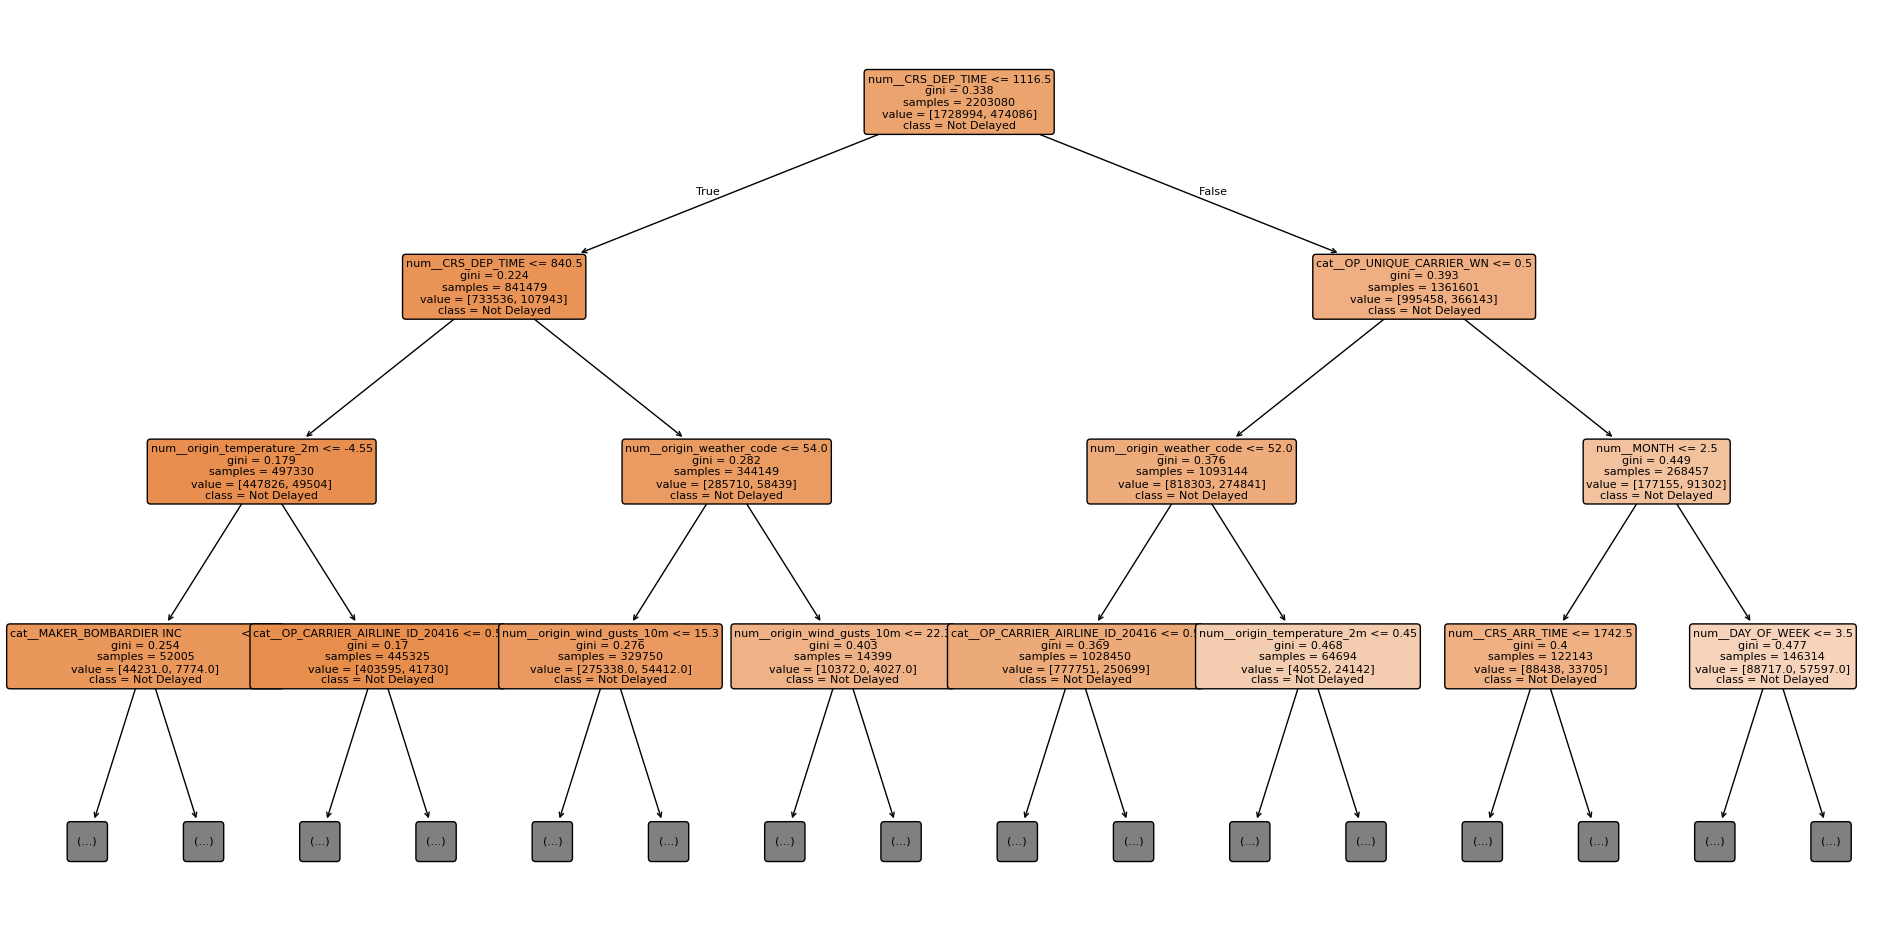

In [ ]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# Extract the decision tree from the pipeline
tree = tree_model.named_steps['classifier']

plt.figure(figsize=(24, 12))

plot_tree(
    tree,
    max_depth=3,
    feature_names=tree_model.named_steps['preprocessor'].get_feature_names_out(),
    class_names=['Not Delayed', 'Delayed'],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.show()

# Regression

In [ ]:
delay = pd.read_csv(
    f'{BASE}/flights_data.csv',
    usecols=['DEP_DELAY']
)

y_reg = delay.loc[flights.index, 'DEP_DELAY']

In [ ]:
from sklearn.tree import DecisionTreeRegressor

regression_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', DecisionTreeRegressor(
        max_depth=10,
        min_samples_leaf=100,
        random_state=42
    ))
])

In [ ]:
X_reg = X.copy()
y_reg = delay.loc[flights.index, 'DEP_DELAY']

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

results_reg = []

for i, (train_idx, val_idx) in enumerate(cv_splits, start=1):

    # Train regression tree
    regression_model.fit(X_reg.loc[train_idx], y_reg.loc[train_idx])

    # Make predictions
    y_pred_reg = regression_model.predict(X_reg.loc[val_idx])

    # Evaluate
    results_reg.append({
        'Split': i,
        'RMSE': mean_squared_error(y_reg.loc[val_idx], y_pred_reg) ** 0.5,
        'MAE': mean_absolute_error(y_reg.loc[val_idx], y_pred_reg),
        'R²': r2_score(y_reg.loc[val_idx], y_pred_reg)
    })

results_reg_df = pd.DataFrame(results_reg)

print(results_reg_df)

   Split       RMSE        MAE        R²
0      1  57.915482  25.668196 -0.114199
1      2  65.465049  27.445026 -0.041275
2      3  54.449713  25.806427 -0.060533
3      4  54.069559  23.212407  0.009135
